In [2]:
# GamePulse - Exploratory Data Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import get_validated_dataset

# Load validated dataset
df = get_validated_dataset()

print("EDA ENVIRONMENT READY")
print("Dataset shape:", df.shape)

Dataset loaded successfully: cookie_cats.csv
Dataset shape: (90189, 5)
Schema validation passed.
Data quality validation passed.

All dataset validations passed!
Total players: 90,189
EDA ENVIRONMENT READY
Dataset shape: (90189, 5)


In [3]:
# Dataset overview

print("DATASET INFORMATION")
print("-" * 40)

df.info()

print("\nSTATISTICAL SUMMARY")
display(df.describe())

print("\nEXPERIMENT GROUPS")
display(df["version"].value_counts())

DATASET INFORMATION
----------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   userid          90189 non-null  int64
 1   version         90189 non-null  str  
 2   sum_gamerounds  90189 non-null  int64
 3   retention_1     90189 non-null  bool 
 4   retention_7     90189 non-null  bool 
dtypes: bool(2), int64(2), str(1)
memory usage: 2.8 MB

STATISTICAL SUMMARY


,userid,sum_gamerounds
count,9.018900e+04,90189.000000
mean,4.998412e+06,51.872457
std,2.883286e+06,195.050858
min,1.160000e+02,0.000000
25%,2.512230e+06,5.000000
50%,4.995815e+06,16.000000
75%,7.496452e+06,51.000000
max,9.999861e+06,49854.000000



EXPERIMENT GROUPS


version
gate_40    45489
gate_30    44700
Name: count, dtype: int64

In [4]:
# Player distribution analysis

player_counts = df["version"].value_counts()

player_percentages = (
    df["version"].value_counts(normalize=True) * 100
)

distribution = pd.DataFrame({
    "Player Count": player_counts,
    "Percentage": player_percentages
})

display(distribution.round(2))

,Player Count,Percentage
version,,
gate_40,45489,50.44
gate_30,44700,49.56


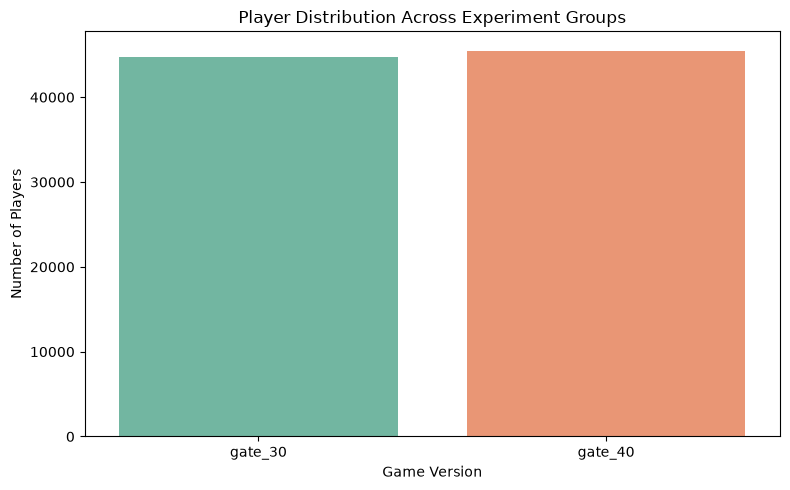

In [5]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="version",
    hue="version",
    palette="Set2",
    legend=False
)

plt.title("Player Distribution Across Experiment Groups")
plt.xlabel("Game Version")
plt.ylabel("Number of Players")

plt.tight_layout()
plt.show()

In [6]:
control_players = (df["version"] == "gate_30").sum()
test_players = (df["version"] == "gate_40").sum()

difference = abs(control_players - test_players)

print("CONTROL GROUP:", control_players)
print("TEST GROUP:", test_players)
print("PLAYER COUNT DIFFERENCE:", difference)
print(
    "GROUP SIZE DIFFERENCE (%):",
    round(difference / len(df) * 100, 2)
)

CONTROL GROUP: 44700
TEST GROUP: 45489
PLAYER COUNT DIFFERENCE: 789
GROUP SIZE DIFFERENCE (%): 0.87


In [7]:
git add notebooks/01_exploratory_data_analysis.ipynb


SyntaxError: invalid decimal literal (4185133813.py, line 1)

In [11]:
# Game rounds statistical analysis

game_round_stats = df.groupby("version")["sum_gamerounds"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(game_round_stats.round(2))


,count,mean,median,std,min,max
version,,,,,,
gate_30,44700,52.46,17.0,256.72,0,49854
gate_40,45489,51.30,16.0,103.29,0,2640


In [12]:
# Game rounds quartile analysis

quartiles = df.groupby("version")["sum_gamerounds"].quantile(
    [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).unstack()

quartiles.columns = [
    "25%", "50%", "75%", "90%", "95%", "99%"
]

display(quartiles.round(2))

,25%,50%,75%,90%,95%,99%
version,,,,,,
gate_30,5.0,17.0,50.0,135.0,222.0,493.00
gate_40,5.0,16.0,52.0,134.0,220.0,492.12


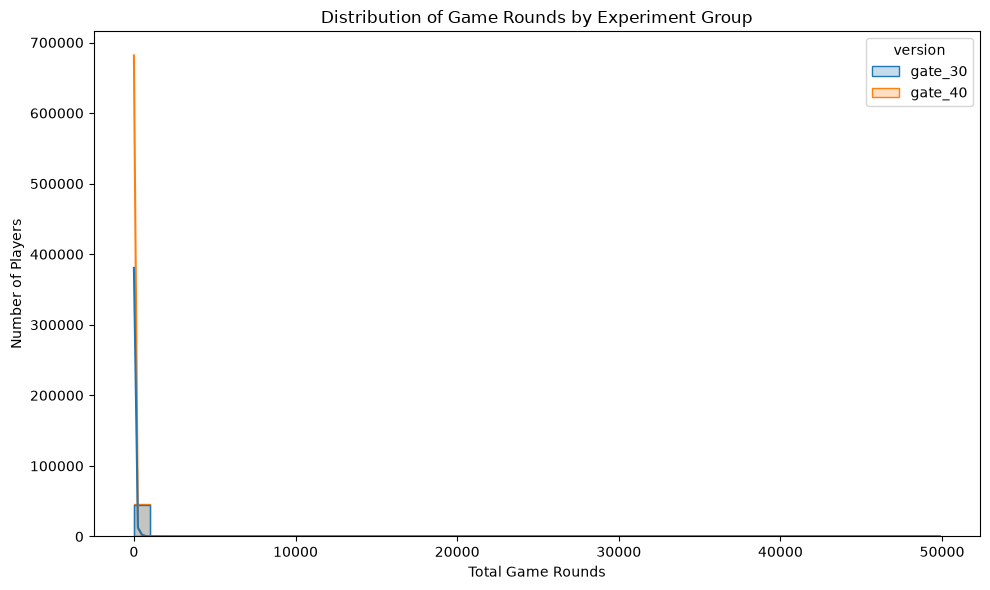

In [13]:
# Game rounds distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="sum_gamerounds",
    hue="version",
    bins=50,
    kde=True,
    element="step"
)

plt.title("Distribution of Game Rounds by Experiment Group")
plt.xlabel("Total Game Rounds")
plt.ylabel("Number of Players")

plt.tight_layout()
plt.show()

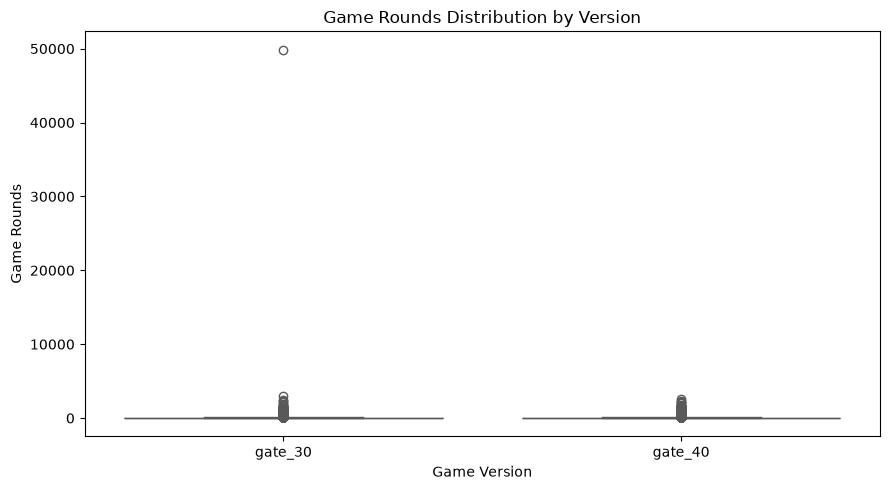

In [14]:
# Box plot of game rounds

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="version",
    y="sum_gamerounds",
    hue="version",
    palette="Set2",
    legend=False
)

plt.title("Game Rounds Distribution by Version")
plt.xlabel("Game Version")
plt.ylabel("Game Rounds")

plt.tight_layout()
plt.show()

In [15]:
# Distribution skewness

skewness = df.groupby("version")["sum_gamerounds"].skew()

print("GAME ROUNDS SKEWNESS")
display(skewness)

GAME ROUNDS SKEWNESS


version
gate_30    163.709871
gate_40      5.967288
Name: sum_gamerounds, dtype: float64